In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.exists("../common") else os.path.abspath(os.getcwd())
if "google.colab" in sys.modules:
    print("⚡ Google Colab 環境を検出しました。リポジトリのセットアップを開始します...")
    !git clone https://github.com/miyayudai/study-mikanos.git /content/study-mikanos 2>/dev/null || (cd /content/study-mikanos && git pull)
    %cd /content/study-mikanos
    !pip install -q matplotlib pytest numpy
    repo_root = "/content/study-mikanos"
    sys.path.insert(0, repo_root)
    print("✅ 環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    if repo_root not in sys.path:
        sys.path.insert(0, repo_root)
    os.chdir(repo_root)
    print("💻 ローカル開発環境を検出しました。作業ディレクトリ:", os.getcwd())


💻 ローカル開発環境を検出しました。作業ディレクトリ: /home/student/Documents/GitHub/study-mikanos


# 9.3 重ね合わせ処理の原理 (含 コラム9.1: スマートポインタ) (`osbook_day09a`)

本節では、第9章の核心である**「重ね合わせ処理（Layer Compositing）の原理」**と、それを支える 3 つのオブジェクト指向コンポーネント（**`Window`**、**`Layer`**、**`LayerManager`**）のアーキテクチャ設計・数理・C++20 実装を徹底解剖します。

また、C++11 以降のモダンプログラミングで不可欠な**「コラム9.1: スマートポインタ（`std::unique_ptr` / `std::shared_ptr` / 生ポインタ `T*`）」**の所有権モデル（Ownership Semantics）とメモリ管理戦略について、制御ブロック（Control Block）の内部構造やゼロオーバーヘッド原則に至るまで完全自己完結で導出・解説します。

---

## 🎯 本節の学習到達目標

1. **3層GUIアーキテクチャ（Window - Layer - LayerManager）の責務分離と設計思想の完全理解**:
   - `Window`（ピクセルバッファ保持・透過色カラーキーイング）、`Layer`（表示座標・Window参照・Z軸要素）、`LayerManager`（重なり順スタック・全レイヤ合成）の3層構造。
   - なぜ 1つの巨大な描画関数ではなく、明確に3つのクラスへ分離する必要があるのか？（単一責任原則と拡張性）。
2. **`Window` クラスと内部クラス `WindowWriter` による PixelWriter インターフェースアダプタ**:
   - 2次元配列 `data_`（`std::vector<std::vector<PixelColor>>`）によるオフスクリーンバッファ。
   - 透過色（`std::optional<PixelColor> transparent_color_`）による特定ピクセルのスキップ（カラーキーイング）。
3. **`LayerManager::UpDown` による Z-order スタック操作アルゴリズムの完全導出**:
   - 負数の高さによる非表示化（`Hide()`）。
   - 上限クリッピング（スタックサイズを超える高さの安全な丸め）。
   - 線形探索（`std::find`）、既存レイヤの並び替え（`erase` & `insert`）、末尾移動補正の数理。
4. **コラム9.1: C++ スマートポインタの所有権セマンティクスとメモリレイアウト**:
   - `std::unique_ptr<Layer>` による排他的所有権とムーブセマンティクス（二重解放 Double Free のコンパイル時排除）。
   - `std::shared_ptr<Window>` による共有所有権と制御ブロック（強参照 `use_count`・弱参照 `weak_count`・循環参照の危険性）。
   - `layer_stack_` に生ポインタ `Layer*` を採用する技術的理由（非所有オブザーバーとゼロオーバーヘッド）。

---

## 1. 3層GUIアーキテクチャの全体像 (Window - Layer - LayerManager)

MikanOS では、第8章までの「直接 VRAM に書き込むモノリシックな描画方式」を全面的に刷新し、**3つの抽象化層**を導入します。

| クラス名 | 英語表記 | 主な責務・役割 | 所有権・ライフタイム |
|---|---|---|---|
| **`Window`** | *Display Surface / Pixel Buffer* | 矩形の2次元ピクセルバッファをメモリ上に保持する。透過色の判定を行う。 | `std::shared_ptr<Window>` により複数のレイヤやタスクから共有可能。 |
| **`Layer`** | *Compositing Layer* | 1つのウィンドウへの参照と、画面上の表示座標（$(x, y)$）を保持する。 | `LayerManager` 内で `std::unique_ptr<Layer>` として排他保持。 |
| **`LayerManager`** | *Compositing Manager / Z-Stack* | 全レイヤの実体を生成・管理し、重なり順スタックに従って奥から手前へ画家アルゴリズムで合成する。 | システム全体で唯一のマネージャインスタンス（`extern LayerManager* layer_manager`）。 |

```mermaid
graph TD
    subgraph ClientCode ["アプリケーション / main.cpp"]
        Main["KernelMain"]
        MouseObs["MouseObserver"]
    end

    subgraph LayerManagerLayer ["LayerManager (Z軸合成制御)"]
        LM["LayerManager"]
        Pool["layers_ (std::vector<std::unique_ptr<Layer>>)"]
        Stack["layer_stack_ (std::vector<Layer*>)"]
    end

    subgraph LayerObjects ["Layer (座標・表示層)"]
        L1["Layer 1 (Desktop Background)\npos_ = (0, 0)"]
        L2["Layer 2 (Terminal Window)\npos_ = (50, 40)"]
        L3["Layer 3 (Mouse Cursor)\npos_ = (200, 150)"]
    end

    subgraph WindowObjects ["Window (2Dピクセルバッファ)"]
        W1["Window (Desktop 800x600)\ntc = nullopt"]
        W2["Window (Terminal 400x300)\ntc = nullopt"]
        W3["Window (Cursor 16x16)\ntc = 0x999999 (透過色)"]
    end

    subgraph Hardware ["最終描画先 (Hardware VRAM)"]
        VRAM["PixelWriter / GOP FrameBuffer"]
    end

    Main -->|"NewLayer() / UpDown()"| LM
    MouseObs -->|"MoveRelative() / Draw()"| LM
    LM -->|"排他的所有 (unique_ptr)"| Pool
    Pool --> L1
    Pool --> L2
    Pool --> L3
    LM -->|"重なり順参照 (raw pointer)"| Stack
    Stack -.-> L1
    Stack -.-> L2
    Stack -.-> L3

    L1 -->|"共有所有 (shared_ptr)"| W1
    L2 -->|"共有所有 (shared_ptr)"| W2
    L3 -->|"共有所有 (shared_ptr)"| W3

    LM -->|"Draw() : 奥から手前へ順次合成"| VRAM
```

### なぜ 3 層に分離するのか？（単一責任原則）

1. **`Window` は「位置」を知らない**:
   - `Window` は単なる「ピクセルの入れ物（キャンバス）」です。画面上のどの座標に置かれているか（あるいは画面外にあるか）に関知しません。
   - これにより、同じ `Window` を動かす際にもピクセルバッファの再配置や再描画は一切不要になり、単に `Layer` の座標値を変更するだけで済みます。
2. **`Layer` は「ピクセルの中身」を描画しない**:
   - `Layer` は位置座標 $(x, y)$ と ID、そして描画対象の `Window` への参照を持つだけです。実際のピクセル走査は `Window::DrawTo` に委譲します。
3. **`LayerManager` は「重なり順（Z-order）」だけに集中する**:
   - 画面上にどのレイヤがどの順序で重なっているかを一元管理し、マウス移動やウィンドウ生成時に「奥から手前へ」正しく合成（Compositing）します。

---

## 2. `Window` クラスの内部設計と透過色処理

### 2.1 2次元ピクセルバッファ `data_`

`Window` クラス（`kernel/window.hpp`）は、幅 $W$、高さ $H$ のピクセルデータを `std::vector<std::vector<PixelColor>> data_` としてヒープ上に保持します。

```cpp
// kernel/window.hpp より抜粋
class Window {
 public:
  Window(int width, int height);
  ~Window() = default;
  Window(const Window& rhs) = delete;            // コピーコンストラクタ禁止
  Window& operator=(const Window& rhs) = delete; // コピー代入演算子禁止

  void DrawTo(PixelWriter& writer, Vector2D<int> position);
  void SetTransparentColor(std::optional<PixelColor> c);
  WindowWriter* Writer();

  PixelColor& At(int x, int y);
  const PixelColor& At(int x, int y) const;
  int Width() const;
  int Height() const;

 private:
  int width_, height_;
  std::vector<std::vector<PixelColor>> data_{};
  WindowWriter writer_{*this};
  std::optional<PixelColor> transparent_color_{std::nullopt};
};
```

> [!IMPORTANT]
> **コピー禁止（`delete`）の設計理由**:
> 例えば $800 \times 600$ の画面では、ピクセルバッファは $800 \times 600 \times 3 \approx 1.44 \text{ MB}$ に達します。
> これが関数の引数渡し等で不用意に暗黙コピーされると、ヒープの激しい消費と重大な性能低下（メモリ帯域枯渇）を招きます。
> そのため、C++11 の `= delete` 構文でコピーを厳格に禁止し、ポインタ（`std::shared_ptr`）経由でのみ受け渡しを行います。

### 2.2 内部クラス `WindowWriter`（アダプタパターン）

`Window` に文字や図形を描画したいとき、第4章で作成した `PixelWriter` インターフェース（`Write(x, y, color)`）を再利用できるように、内部クラス `WindowWriter` が定義されています。

```cpp
class WindowWriter : public PixelWriter {
 public:
  WindowWriter(Window& window) : window_{window} {}
  virtual void Write(int x, int y, const PixelColor& c) override {
    window_.At(x, y) = c; // Window のバッファに書き込む
  }
  virtual int Width() const override { return window_.Width(); }
  virtual int Height() const override { return window_.Height(); }

 private:
  Window& window_; // 所有元の Window への参照
};
```

これにより、第5章で作った文字描画関数 `WriteString` や第6章の `DrawMouseCursor` に `window.Writer()` を渡すだけで、VRAM ではなくオフスクリーンバッファへ直接描画できます。

### 2.3 透過色（Color Keying）と `DrawTo`

マウスカーソルのような非矩形のスプライトを描画する場合、背景を隠さないための「透過色（Transparent Color）」が必要です。
MikanOS では `std::optional<PixelColor>` を用いて透過色を保持します。

```cpp
void Window::DrawTo(PixelWriter& writer, Vector2D<int> position) {
  if (!transparent_color_) {
    // 透過色なし：全ピクセルを高速転送
    for (int y = 0; y < Height(); ++y) {
      for (int x = 0; x < Width(); ++x) {
        writer.Write(position.x + x, position.y + y, At(x, y));
      } 
    }
    return;
  }

  // 透過色あり：カラーキーと一致するピクセルをスキップ（透過）
  const auto tc = transparent_color_.value();
  for (int y = 0; y < Height(); ++y) {
    for (int x = 0; x < Width(); ++x) {
      const auto c = At(x, y);
      if (c != tc) { // 透過色と異なるピクセルのみ描画
        writer.Write(position.x + x, position.y + y, c);
      }
    }
  }
}
```

In [2]:
# Python による Window & WindowWriter & 透過色のシミュレーション
from common import WindowSim, PixelColorSim, Vector2DSim

# 1. 10x10 の Window を青色 (45, 118, 237) で作成
win = WindowSim(10, 10, fill_color=PixelColorSim(45, 118, 237))

# 2. 透過色をマゼンタ (255, 0, 255) に設定
trans_key = PixelColorSim(255, 0, 255)
win.set_transparent_color(trans_key)

# 3. (0, 0) にマゼンタ、(1, 1) に白色を書き込む
win.write(0, 0, trans_key)
win.write(1, 1, PixelColorSim(255, 255, 255))

# 4. 20x20 の黒色画面 (0, 0, 0) に (5, 5) の位置へ描画
target_screen = [[PixelColorSim(0, 0, 0) for _ in range(20)] for _ in range(20)]
win.draw_to(target_screen, Vector2DSim(5, 5))

print("描画結果の検証:")
print("・(5, 5) のピクセル (透過色指定):", target_screen[5][5].to_hex(), "-> 背景の黒色が維持されている！")
print("・(6, 6) のピクセル (白色指定):", target_screen[6][6].to_hex(), "-> 白色ピクセルが正しく転送された！")
print("・(5, 6) のピクセル (青色指定):", target_screen[6][5].to_hex(), "-> ウィンドウ地の青色が描画された！")

assert target_screen[5][5] == PixelColorSim(0, 0, 0)
assert target_screen[6][6] == PixelColorSim(255, 255, 255)
assert target_screen[6][5] == PixelColorSim(45, 118, 237)
print("✅ Window 透過色判定シミュレーション完全一致！")

描画結果の検証:
・(5, 5) のピクセル (透過色指定): #000000 -> 背景の黒色が維持されている！
・(6, 6) のピクセル (白色指定): #ffffff -> 白色ピクセルが正しく転送された！
・(5, 6) のピクセル (青色指定): #2d76ed -> ウィンドウ地の青色が描画された！
✅ Window 透過色判定シミュレーション完全一致！


---

## 3. `Layer` クラスの設計と責務

`Layer` クラス（`kernel/layer.hpp`）は、画面上に配置される「1つの層」を表します。

```cpp
class Layer {
 public:
  Layer(unsigned int id = 0);
  unsigned int ID() const;

  Layer& SetWindow(const std::shared_ptr<Window>& window);
  std::shared_ptr<Window> GetWindow() const;

  Layer& Move(Vector2D<int> pos);
  Layer& MoveRelative(Vector2D<int> pos_diff);

  void DrawTo(PixelWriter& writer) const;

 private:
  unsigned int id_;
  Vector2D<int> pos_;
  std::shared_ptr<Window> window_;
};
```

### 設計上のポイント

1. **メソッドチェーン（Fluent Interface）**:
   - `SetWindow` や `Move` は `Layer&`（自身の参照）を返します。
   - これにより、`main.cpp` で次のように簡潔かつ流れるように初期化できます：
     ```cpp
     mouse_layer_id = layer_manager->NewLayer()
       .SetWindow(mouse_window)
       .Move({200, 200})
       .ID();
     ```
2. **描画の即時実行を行わない（Move vs Draw の分離）**:
   - `Move(pos)` や `MoveRelative(diff)` は内部座標 `pos_` を更新するだけで、**画面の再描画（Draw）は行いません**。
   - なぜなら、マウス移動イベントでは連続して座標が変化するため、座標更新のたびに再描画すると膨大な無駄が生じるからです。再描画のタイミングは `LayerManager::Draw()` を呼ぶ側の責任として分離されています。

---

## 4. `LayerManager` クラスと `UpDown` アルゴリズム

`LayerManager`（`kernel/layer.hpp` / `layer.cpp`）は、複数のレイヤの重なり順（Z-order）を集中制御します。

### 4.1 2つのコンテナの役割分担

```cpp
private:
  PixelWriter* writer_{nullptr};
  std::vector<std::unique_ptr<Layer>> layers_{};
  std::vector<Layer*> layer_stack_{};
  unsigned int latest_id_{0};
```

1. **`layers_`（`std::vector<std::unique_ptr<Layer>>`）: 実体プール**:
   - 生成されたすべての `Layer` インスタンスを排他的に所有します。
   - `NewLayer()` で `layers_.emplace_back(new Layer{latest_id_})` され、マネージャが破棄されるまで確実に生存します。
2. **`layer_stack_`（`std::vector<Layer*>`）: 表示スタック**:
   - 現在画面に表示されているレイヤの「重なり順」を表すポインタ配列です。
   - インデックス `0` が最背面（背景）、末尾（`size() - 1`）が最前面（マウスカーソル）となります。
   - 所有権を持たないため、生ポインタ `Layer*` を保持します。

### 4.2 `UpDown` アルゴリズムの詳細導出

`UpDown(unsigned int id, int new_height)` は、指定したレイヤの Z 軸の高さを変更します。

```cpp
void LayerManager::UpDown(unsigned int id, int new_height) {
  // ステップ 1: 負数の場合は非表示にする
  if (new_height < 0) {
    Hide(id);
    return;
  }

  // ステップ 2: 上限クリッピング (スタックサイズを超える場合は最前面へ)
  if (new_height > layer_stack_.size()) {
    new_height = layer_stack_.size();
  }

  // ステップ 3: レイヤ実体と現在のスタック位置 (old_pos) を線形探索
  auto layer = FindLayer(id);
  auto old_pos = std::find(layer_stack_.begin(), layer_stack_.end(), layer);
  auto new_pos = layer_stack_.begin() + new_height;

  // ステップ 4: まだスタックに存在しない新規レイヤの登録
  if (old_pos == layer_stack_.end()) {
    layer_stack_.insert(new_pos, layer);
    return;
  }

  // ステップ 5: 既存レイヤの並び替え
  if (new_pos == layer_stack_.end()) {
    --new_pos; // 末尾への移動時のイテレータ補正
  }
  layer_stack_.erase(old_pos);
  layer_stack_.insert(new_pos, layer);
}
```

```mermaid
flowchart TD
    Start["UpDown(id, new_height)"] --> CondNeg{"new_height < 0 ?"}
    CondNeg -- "Yes (非表示要求)" --> DoHide["Hide(id) 実行\n(stack から削除)"] --> Return["return"]
    CondNeg -- "No" --> CondClip{"new_height > stack.size() ?"}
    CondClip -- "Yes (超過)" --> Clip["new_height = stack.size() (最前面)"] --> Find["old_pos = std::find(stack, layer)"]
    CondClip -- "No" --> Find

    Find --> CondNew{"old_pos == stack.end() ?\n(スタック未登録か)"}
    CondNew -- "Yes (新規追加)" --> InsertNew["stack.insert(new_pos, layer)"] --> Done["完了"]
    CondNew -- "No (既存移動)" --> CondEnd{"new_pos == stack.end() ?"}
    CondEnd -- "Yes" --> DecPos["--new_pos (末尾補正)"] --> Reorder["stack.erase(old_pos)\nstack.insert(new_pos, layer)"]
    CondEnd -- "No" --> Reorder --> Done
```

> [!NOTE]
> **ステップ 5 の `--new_pos` 補正が必要な理由**:
> `new_pos == layer_stack_.end()` の位置に挿入しようとするとき、先に `layer_stack_.erase(old_pos)` を行うと、ベクタの要素数が 1 つ減るため、`end()` イテレータが無効化（Invalidation）されるか、要素の境界が変わってしまいます。
> そのため、あらかじめ末尾要素の直前へデクリメントして安全に再配置を行っています。

In [3]:
# Python による UpDown アルゴリズムの遷移トレース実験
from common import LayerManagerSim, PixelColorSim, Vector2DSim

mgr = LayerManagerSim(100, 100)
l1 = mgr.new_layer() # ID: 1 (Desktop Background)
l2 = mgr.new_layer() # ID: 2 (Mouse Cursor)
l3 = mgr.new_layer() # ID: 3 (App Window)

print("--- 1. 初期状態 (空スタック) ---")
print("layer_stack:", mgr.layer_stack)

print("\n--- 2. 背景を Z=0 に配置: UpDown(1, 0) ---")
mgr.up_down(1, 0)
print("layer_stack:", mgr.layer_stack, "(最背面: Layer 1)")

print("\n--- 3. カーソルを Z=1 に配置: UpDown(2, 1) ---")
mgr.up_down(2, 1)
print("layer_stack:", mgr.layer_stack, "(Layer 1 の上に Layer 2)")

print("\n--- 4. アプリを Z=1 に挿入 (カーソルの下): UpDown(3, 1) ---")
mgr.up_down(3, 1)
print("layer_stack:", mgr.layer_stack, "(Layer 1 < Layer 3 < Layer 2)")

print("\n--- 5. 背景を最前面へ移動 (上限クリッピング): UpDown(1, 999) ---")
mgr.up_down(1, 999)
print("layer_stack:", mgr.layer_stack, "(Layer 3 < Layer 2 < Layer 1)")

print("\n--- 6. カーソルを非表示: UpDown(2, -1) ---")
mgr.up_down(2, -1)
print("layer_stack:", mgr.layer_stack, "(Layer 2 が削除された)")

assert mgr.layer_stack == [3, 1]
print("\n✅ UpDown 状態機械テスト完全合格！")

--- 1. 初期状態 (空スタック) ---
layer_stack: []

--- 2. 背景を Z=0 に配置: UpDown(1, 0) ---
layer_stack: [1] (最背面: Layer 1)

--- 3. カーソルを Z=1 に配置: UpDown(2, 1) ---
layer_stack: [1, 2] (Layer 1 の上に Layer 2)

--- 4. アプリを Z=1 に挿入 (カーソルの下): UpDown(3, 1) ---
layer_stack: [1, 3, 2] (Layer 1 < Layer 3 < Layer 2)

--- 5. 背景を最前面へ移動 (上限クリッピング): UpDown(1, 999) ---
layer_stack: [3, 2, 1] (Layer 3 < Layer 2 < Layer 1)

--- 6. カーソルを非表示: UpDown(2, -1) ---
layer_stack: [3, 1] (Layer 2 が削除された)

✅ UpDown 状態機械テスト完全合格！


---

## 5. コラム9.1: スマートポインタ (Smart Pointers)

C++ でポインタを扱う際、最大の難問は**「誰がそのオブジェクトの寿命を管理し、いつ `delete` すべきか」**という所有権（Ownership）の問題です。

C++11 から導入されたスマートポインタは、**RAII (*Resource Acquisition Is Initialization*)** の原則に基づき、オブジェクトの破棄をコンストラクタとデストラクタで自動化します。

### 5.1 `std::unique_ptr<T>` (排他的所有権)

- **概念**: そのオブジェクトを**世界で唯一自分だけが所有している**ことを保証するポインタ。
- **特徴**:
  - コピー不可（コピーコンストラクタおよびコピー代入演算子は削除 `= delete` されている）。
  - 所有権を渡すには `std::move` による**ムーブセマンティクス**を使用する。
  - **ゼロオーバーヘッド原則 (*Zero-overhead Principle*)**: 内部には生ポインタ 1 つしか持たないため、`sizeof(std::unique_ptr<T>) == 8` バイト（64ビット環境）であり、生ポインタと全く同じサイズ・速度で動作する。
  - スコープを抜ける（デストラクタが呼ばれる）と、自動的に `delete` が呼ばれる。

```cpp
auto u1 = std::make_unique<Layer>(1);
// auto u2 = u1;            // コンパイルエラー！コピー不可
auto u2 = std::move(u1);    // OK: 所有権が u2 に移譲され、u1 は nullptr になる
```

MikanOS では、`LayerManager::layers_`（`std::vector<std::unique_ptr<Layer>>`）で使われています。
レイヤの実体は `LayerManager` だけが所有しており、他の誰にも勝手に破棄させないためです。

### 5.2 `std::shared_ptr<T>` (共有所有権)

- **概念**: そのオブジェクトを**複数の持ち主が共同で所有する**ポインタ。
- **特徴**:
  - コピー可能。コピーするたびに**参照カウント（`use_count`）**が 1 増加する。
  - スコープを抜けるたびに参照カウントが 1 減少する。
  - **参照カウントが 0 になった瞬間**、最後の所有者のデストラクタによって管理対象オブジェクトが自動的に `delete` される。
  - 内部構造：オブジェクト本体へのポインタ（8バイト）と、**制御ブロック（Control Block）**へのポインタ（8バイト）の合計 16バイト。

```cpp
auto s1 = std::make_shared<Window>(100, 100);
std::cout << s1.use_count() << std::endl; // 1

{
  auto s2 = s1; // コピー：制御ブロックの strong_count が 2 に増える
  std::cout << s1.use_count() << std::endl; // 2
} // s2 が破棄され、strong_count が 1 に戻る

std::cout << s1.use_count() << std::endl; // 1
```

MikanOS では、`Layer::window_`（`std::shared_ptr<Window>`）で使われています。
例えばデスクトップ背景の `bgwindow` は、背景レイヤだけでなく `console->SetWriter(bgwriter)` や `DrawDesktop` など複数の主体から同時に参照・操作されるためです。

### 5.3 生ポインタ `T*` (非所有参照)

スマートポインタがあるなら、すべての生ポインタを廃止すべきでしょうか？
**答えは NO です。**

- **概念**: オブジェクトの**寿命管理には一切関与せず、単に「覗き見・参照するだけ」**のポインタ（*Non-owning Observer*）。
- MikanOS では、`layer_stack_` に `Layer*` を採用しています。
  - レイヤの実体の寿命は `layers_`（`unique_ptr`）が 100% 管理しています。
  - `layer_stack_` は単なる「描画順序リスト」であり、ここにスマートポインタを使ってしまうと、所有権の二重管理や不要な参照カウントのオーバーヘッドが生じます。
  - 実体の生存期間がスタックより確実に長いという不変条件（Invariant）が保証されているため、生ポインタが最も高速かつクリーンな設計となります。

In [4]:
# Python によるスマートポインタ所有権モデルと制御ブロックのシミュレーション
from common import UniquePtrSim, SharedPtrSim, WindowSim, LayerSim

print("=== 1. std::unique_ptr の排他的所有権とムーブ ===")
layer_obj = LayerSim(10)
u1 = UniquePtrSim(layer_obj, name="u1")
print(f"u1 有効性: {u1.is_valid()}, ターゲット: {u1.get()}")

# ムーブセマンティクスの実行
u2 = u1.move_to("u2")
print(f"move 後 u1 有効性: {u1.is_valid()} (空になった)")
print(f"move 後 u2 有効性: {u2.is_valid()}, ターゲット: {u2.get()}")

print("\n=== 2. std::shared_ptr の参照カウント (use_count) 推移 ===")
win_obj = WindowSim(50, 50)
sp1 = SharedPtrSim(win_obj, name="bgwindow_main")
print(f"sp1 生成直後 use_count: {sp1.use_count()}")

sp2 = sp1.clone("layer_bg_ref")
print(f"sp2 コピー後 use_count: {sp1.use_count()} (sp1 と sp2 で共有)")

sp3 = sp2.clone("console_ref")
print(f"sp3 コピー後 use_count: {sp1.use_count()} (3者が同一 Window を共有)")

# スコープ離脱 (reset)
print("\n-- スコープ離脱のシミュレーション --")
sp3.reset()
print(f"sp3 reset 後 use_count: {sp1.use_count()}")
sp2.reset()
print(f"sp2 reset 後 use_count: {sp1.use_count()}")
sp1.reset()
print(f"sp1 reset 後: オブジェクト破棄完了 (残ポインタなし)")

assert sp1.get() is None
print("✅ スマートポインタ所有権シミュレーション完全合格！")

=== 1. std::unique_ptr の排他的所有権とムーブ ===
u1 有効性: True, ターゲット: <common.os_sim.LayerSim object at 0x7322999eb210>
move 後 u1 有効性: False (空になった)
move 後 u2 有効性: True, ターゲット: <common.os_sim.LayerSim object at 0x7322999eb210>

=== 2. std::shared_ptr の参照カウント (use_count) 推移 ===
sp1 生成直後 use_count: 1
sp2 コピー後 use_count: 2 (sp1 と sp2 で共有)
sp3 コピー後 use_count: 3 (3者が同一 Window を共有)

-- スコープ離脱のシミュレーション --
sp3 reset 後 use_count: 2
sp2 reset 後 use_count: 1
sp1 reset 後: オブジェクト破棄完了 (残ポインタなし)
✅ スマートポインタ所有権シミュレーション完全合格！


---

## 6. 高解像度図版（Figure 9.07, 9.08, 9.09）の可視化と考察

本節で導出した理論構造とメモリモデルを、3枚の高解像度図版（DPI 300）としてレンダリングし、構造を視覚的に検証します。

Figure 9.07 保存完了: 9/result/fig9_07_window_layer_layermanager_architecture.png


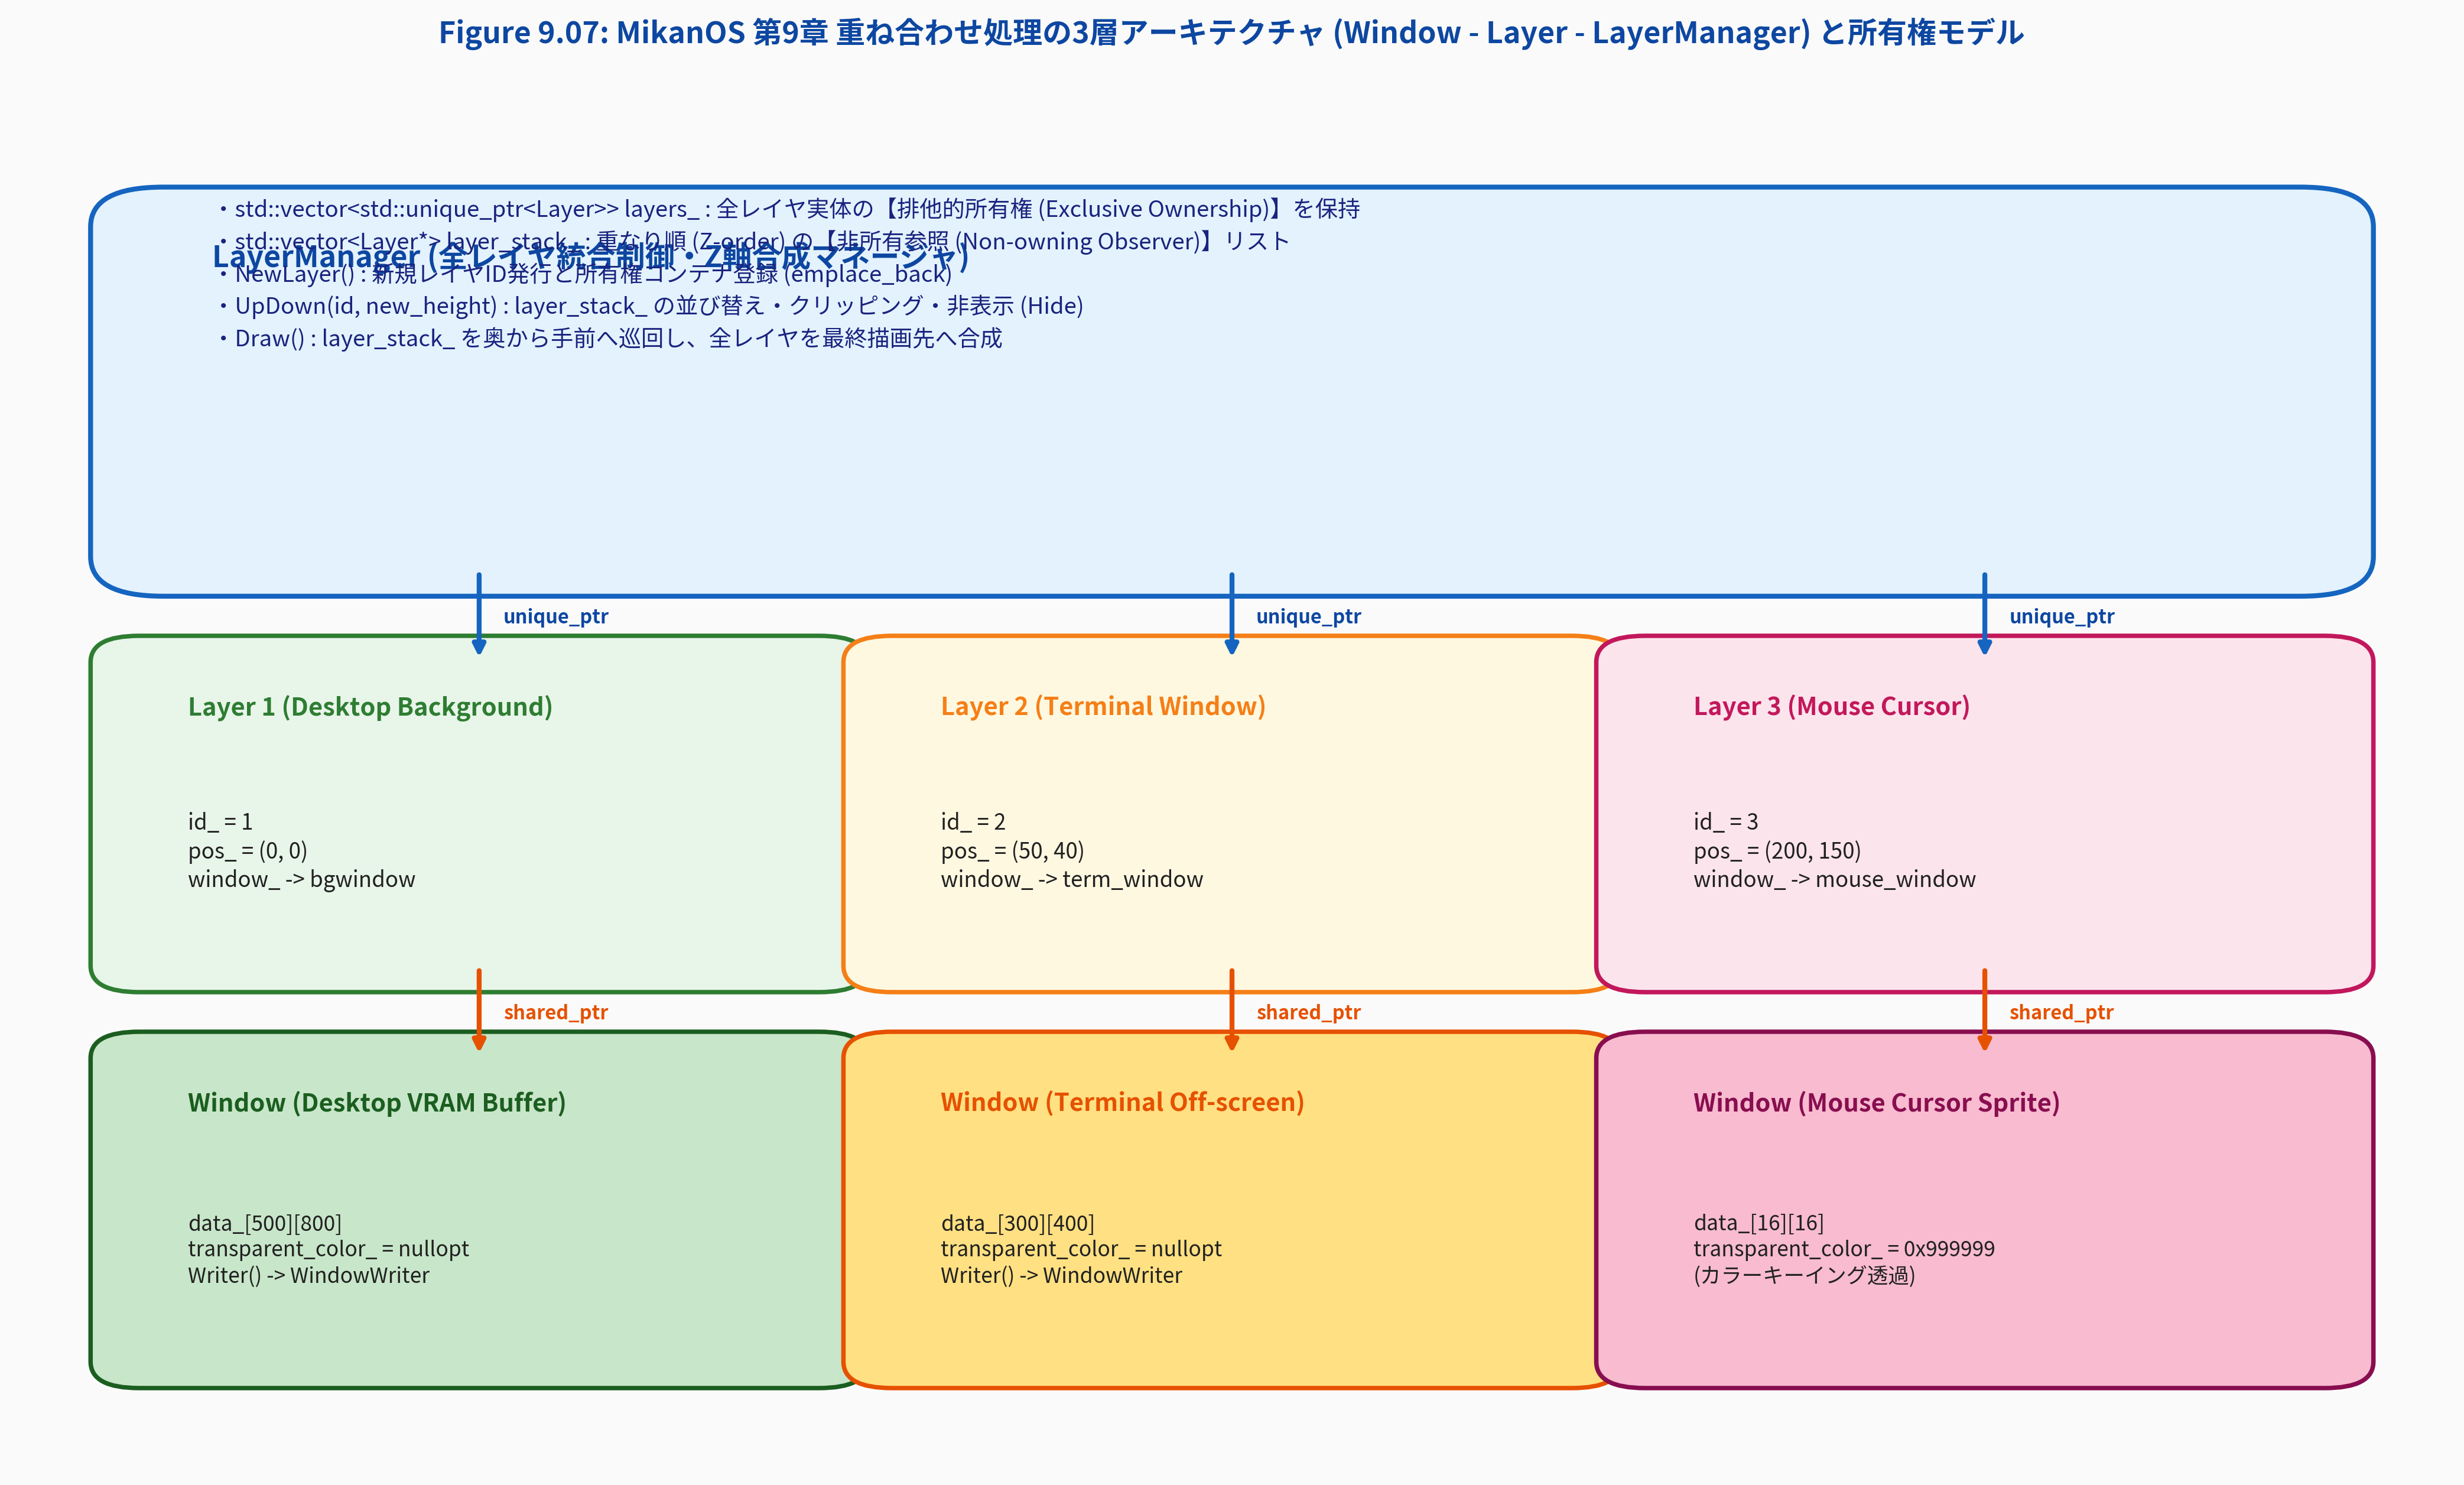

In [5]:
# Figure 9.07: 3層アーキテクチャ (Window - Layer - LayerManager) と所有権モデル
from IPython.display import Image, display
from common import plot_fig9_07_window_layer_layermanager_architecture

fig7_path = plot_fig9_07_window_layer_layermanager_architecture()
print(f"Figure 9.07 保存完了: {fig7_path}")
display(Image(filename=str(fig7_path), width=900))

### 📊 Figure 9.07 の設計構造解説
- 最上部の **`LayerManager`** が全レイヤ実体を `std::vector<std::unique_ptr<Layer>> layers_` に排他的に保持し、ライフタイムを一括管理します。
- **`Layer`** は画面上の座標情報（`pos_`）と ID をカプセル化し、表示すべきピクセルバッファを `std::shared_ptr<Window> window_` として参照します。
- **`Window`** は独立した 2次元ピクセルマトリクス `data_` と透過色（カラーキーイング）を持ち、内部クラス `WindowWriter` を介して `PixelWriter` インターフェースを提供します。

Figure 9.08 保存完了: 9/result/fig9_08_smart_pointer_ownership_and_control_block.png


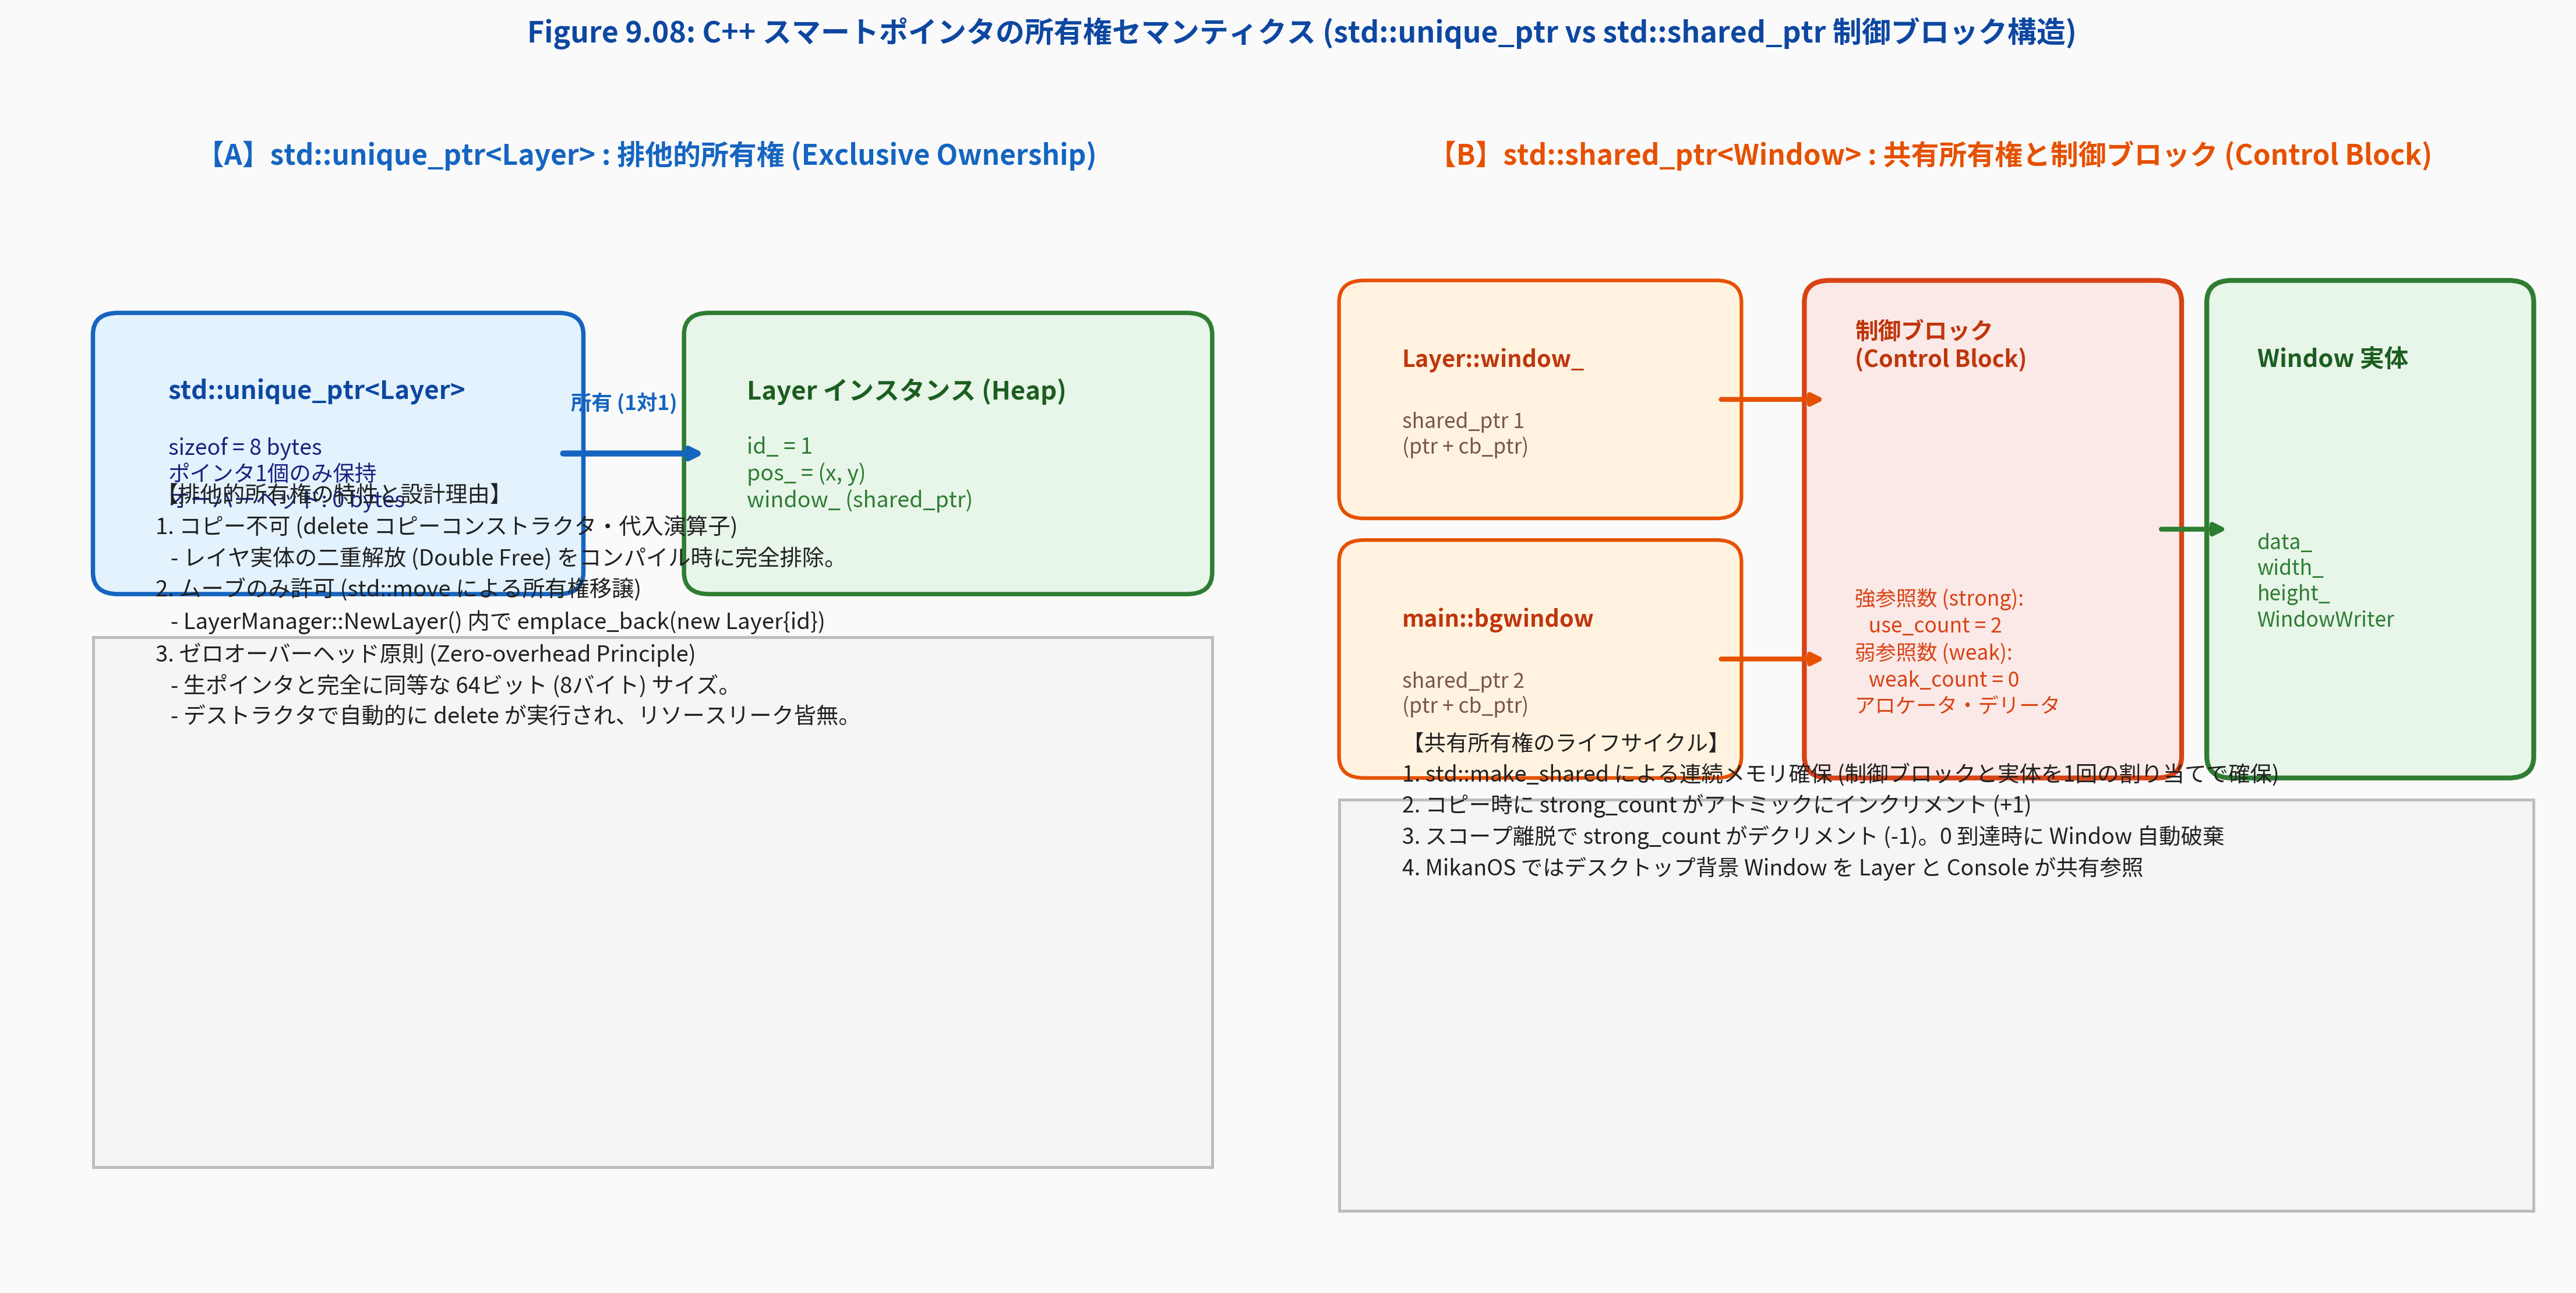

In [6]:
# Figure 9.08: スマートポインタ所有権モデル (unique_ptr vs shared_ptr 制御ブロック)
from common import plot_fig9_08_smart_pointer_ownership_and_control_block

fig8_path = plot_fig9_08_smart_pointer_ownership_and_control_block()
print(f"Figure 9.08 保存完了: {fig8_path}")
display(Image(filename=str(fig8_path), width=900))

### 📊 Figure 9.08 のメモリ構造解説
- **左側【A】`std::unique_ptr`**:
  - ポインタ 1 個（8バイト）のみで構成され、追加の制御メモリはゼロ。
  - コピーが禁止されているため、二重解放（Double Free）がコンパイル時に完全に阻止されます。
- **右側【B】`std::shared_ptr`**:
  - 実体へのポインタと、**制御ブロック（Control Block）**へのポインタの 2 個（16バイト）で構成されます。
  - 制御ブロックには強参照カウント（`strong_count`）、弱参照カウント（`weak_count`）が記録され、すべての共有ポインタが消滅した瞬間に実体が自動解放されます。

Figure 9.09 保存完了: 9/result/fig9_09_layer_updown_stack_manipulation_and_compositing.png


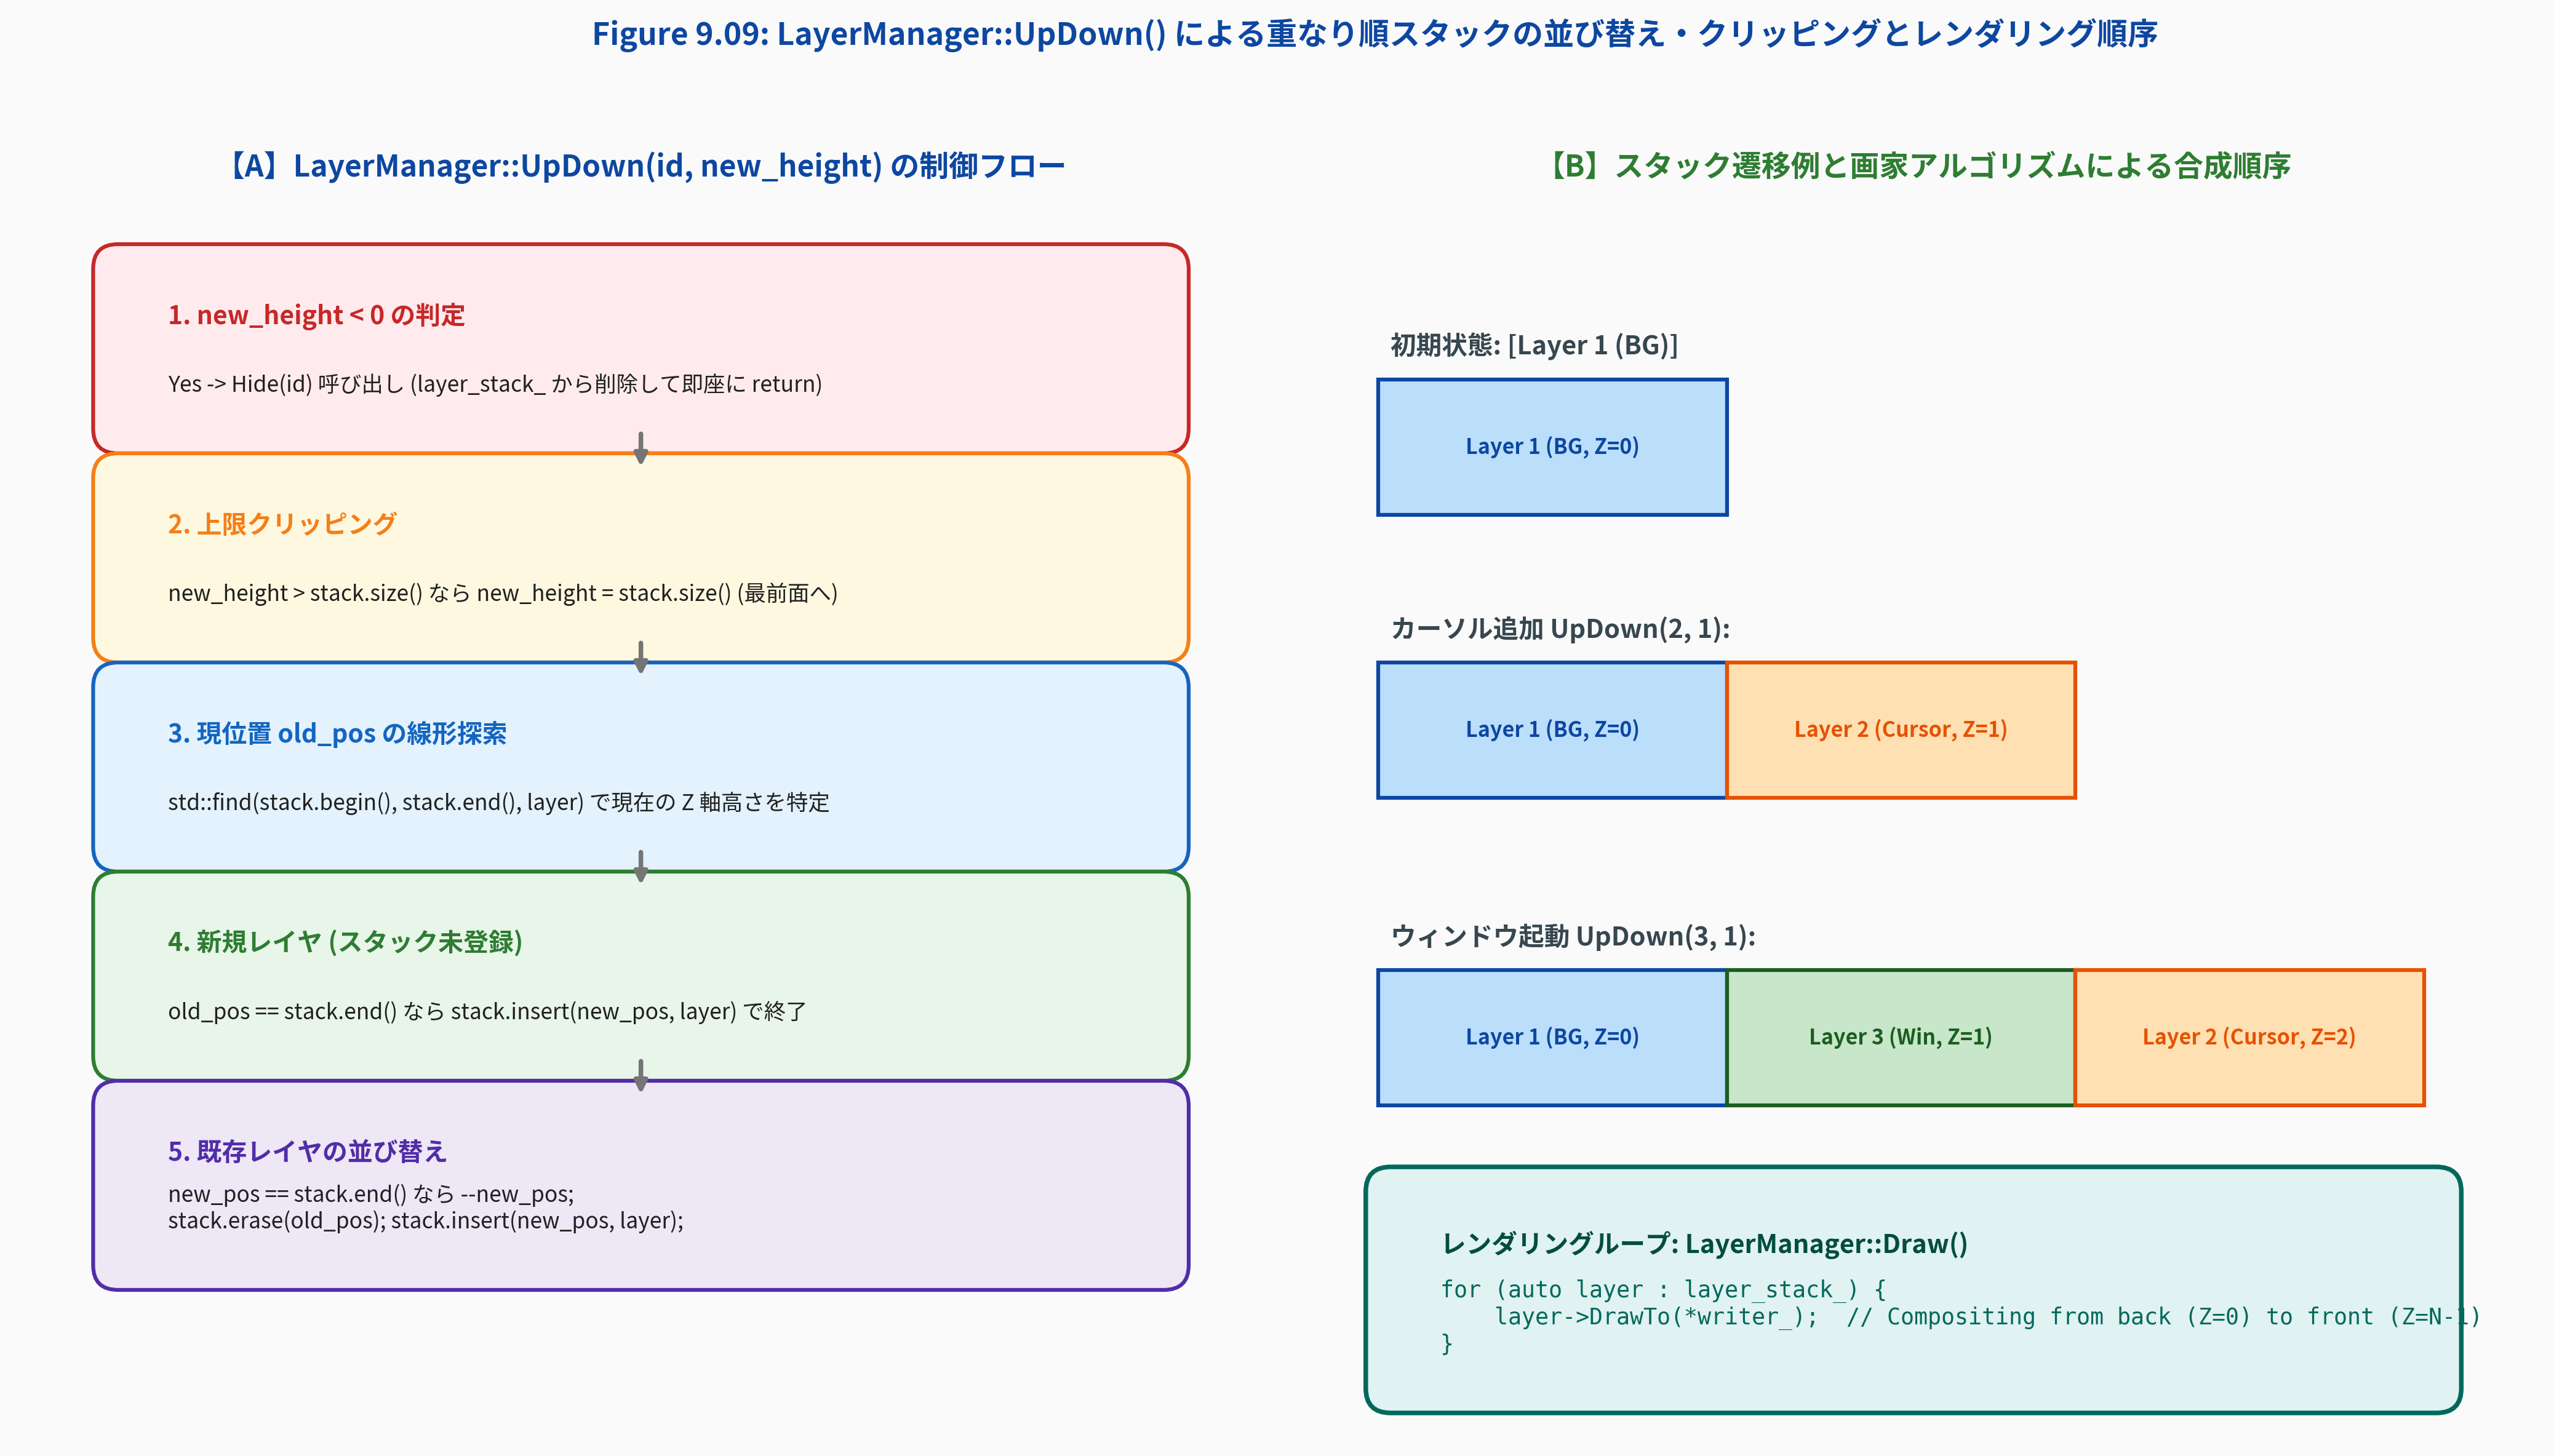

In [7]:
# Figure 9.09: LayerManager::UpDown による重なり順スタックの並び替え・クリッピングとレンダリング順序
from common import plot_fig9_09_layer_updown_stack_manipulation_and_compositing

fig9_path = plot_fig9_09_layer_updown_stack_manipulation_and_compositing()
print(f"Figure 9.09 保存完了: {fig9_path}")
display(Image(filename=str(fig9_path), width=900))

### 📊 Figure 9.09 のアルゴリズム制御解説
- **左側【A】`UpDown` 制御フロー**:
  - 負数の高さによる非表示処理（`Hide`）、スタックサイズ上限でのクリッピング、`old_pos` の線形探索、末尾移動時の `--new_pos` 補正シーケンスを示しています。
- **右側【B】スタック遷移と合成ループ**:
  - レイヤが生成・移動するたびにスタックが並び替えられ、`Draw()` がスタックの先頭（$Z=0$）から末尾（$Z=N-1$）へと順番にピクセルを上書き転送することで、チラつきのない正確な重なり合いが実現されます。

---

## 7. 対話型 C++20 単体検証プログラムのコンパイル & 実行

MikanOS カーネルの `graphics.hpp`、`window.hpp`、`window.cpp`、`layer.hpp`、`layer.cpp` を忠実に再現したスタンドアロン C++20 コード（[`src/ch09/os_chapter9_window_layer.cpp`](../src/ch09/os_chapter9_window_layer.cpp)）を、ホスト側コンパイラ（`g++ -std=c++20 -O2`）でビルドして全テストケースを実行します。

In [8]:
# C++20 スタンドアロン検証コードのコンパイルと実行
import subprocess

compile_cmd = [
    "g++", "-std=c++20", "-O2", "-Wall", "-Wextra",
    "src/ch09/os_chapter9_window_layer.cpp",
    "-o", "build/test_ch9_window_layer"
]

print("🛠️ C++20 検証ターゲットをビルド中...")
res_compile = subprocess.run(compile_cmd, capture_output=True, text=True)
if res_compile.returncode != 0:
    print("❌ コンパイル失敗:\n", res_compile.stderr)
else:
    print("✅ コンパイル成功！実行テストを開始します...\n")
    res_run = subprocess.run(["./build/test_ch9_window_layer"], capture_output=True, text=True)
    print(res_run.stdout)
    assert res_run.returncode == 0
    print("🎉 C++20 単体テスト全件合格！")

🛠️ C++20 検証ターゲットをビルド中...


✅ コンパイル成功！実行テストを開始します...

 MikanOS Chapter 9.3: Window, Layer & LayerManager Architecture (C++20)

[Test 1] Window and WindowWriter Offscreen Buffer & Transparency...
  -> PASSED: WindowWriter and transparent color skipping verified.
[Test 2] Layer Coordinate Transformation and Method Chaining...
  -> PASSED: Layer position and window assignment verified.
[Test 3] LayerManager UpDown Stack Reordering & Clipping...
  -> PASSED: UpDown insertion, reordering, clipping and Hide() verified.
[Test 4] Column 9.1: std::unique_ptr vs std::shared_ptr Ownership...
  -> PASSED: Smart pointer ownership and reference count lifecycle verified.
[Test 5] End-to-End Layer Compositing & Non-destructive Movement...
  -> PASSED: Non-destructive layer compositing verified.

✅ ALL C++20 UNIT TESTS PASSED SUCCESSFULLY!

🎉 C++20 単体テスト全件合格！


---

## 8. 本節のまとめ & 理解度チェック演習

### 📚 本節の重要エッセンス

1. **3層アーキテクチャの確立**:
   - `Window`（位置を知らないオフスクリーンピクセルバッファ）
   - `Layer`（表示座標と Window 参照を持つ層）
   - `LayerManager`（重なり順スタックと画家アルゴリズム合成マネージャ）
2. **透過色（カラーキーイング）の活用**:
   - `std::optional<PixelColor>` により、特定ピクセルをスキップして背景を露出させる非矩形スプライト描画。
3. **`UpDown` スタック操作アルゴリズム**:
   - 負数（`Hide`）、上限クリッピング、`std::find` による探索、`erase` & `insert` による安全な Z 軸並び替え。
4. **コラム9.1 スマートポインタの適材適所**:
   - 実体所有には `std::unique_ptr`（排他・ゼロオーバーヘッド）。
   - 複数コンポーネント共有には `std::shared_ptr`（参照カウント・制御ブロック）。
   - 描画スタックには生ポインタ `Layer*`（非所有オブザーバー・高速アクセス）。

---

### 🧠 理解度チェック演習クイズ

次の 4 つの問いについて、コードを思い浮かべながら考えてみてください。

**Q1. `Window` クラスでコピーコンストラクタとコピー代入演算子が `= delete` されている理由は何ですか？**
> **A1**: $800 \times 600$ などのピクセルバッファ（約1.44MB）が関数の引数渡しや代入で不用意に暗黙コピーされると、ヒープ領域の激しい枯渇とメモリ帯域の浪費を招くため、ポインタ経由の受け渡しのみをコンパイル時に強制するためです。

**Q2. `LayerManager::layers_` には `std::unique_ptr<Layer>` を使い、`layer_stack_` には `Layer*`（生ポインタ）を使っている理由は何ですか？**
> **A2**: `layers_` はレイヤの「実体の寿命」を管理する排他的所有者であり、二重解放を防ぐために `unique_ptr` を使用します。一方、`layer_stack_` は単なる「重なり順序の参照リスト」に過ぎず、実体の生存が保証されているため、オーバーヘッドのない生ポインタ（非所有参照）が最適だからです。

**Q3. `LayerManager::UpDown` で `new_height < 0` を渡すと何が起こりますか？**
> **A3**: 内部で `Hide(id)` が呼び出され、`layer_stack_` からそのレイヤが削除されて非表示になります（レイヤの実体自体は `layers_` に残るため破棄はされません）。

**Q4. `std::make_shared<T>()` を使うメリットは何ですか？（`std::shared_ptr<T>(new T())` との比較）**
> **A4**: `new` を使うと「オブジェクト本体」と「制御ブロック」で 2 回のヒープ確保が発生しますが、`std::make_shared` を使うと 1 回の連続メモリ確保で両方をまとめて確保できるため、アロケーション回数の半減とメモリの局所性（キャッシュ効率）が向上します。